# Human Activity Recognition with a Hidden Markov Model

Recognising **standing, walking, jumping and still** from smartphone accelerometer and gyroscope signals with a Hidden Markov Model implemented from scratch in NumPy.

| Section | Content |
|---|---|
| 1 | Data collection and quality checks |
| 2 | Preprocessing and windowing |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))

from src import preprocessing as pp

PLOTS = ROOT / "plots"
PLOTS.mkdir(exist_ok=True)

ACTIVITIES = pp.ACTIVITIES
COLORS = {"standing": "#4C72B0", "walking": "#55A868", "jumping": "#C44E52", "still": "#8172B2"}
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)

## 1. Data collection

All recordings were made with **Sensor Logger 1.68 on an iPhone 13** at a nominal 100 Hz (10 ms). Each training clip is one activity lasting 5–10 s; the two test files are continuous sessions containing all four activities.

In [2]:
summary = pd.read_csv(ROOT / "data" / "dataset_summary.csv")
train_summary = summary[~summary["file"].str.startswith("mixed")]

per_activity = (train_summary.groupby("activity")
                .agg(clips=("file", "count"), total_s=("duration_s", "sum"),
                     min_s=("duration_s", "min"), max_s=("duration_s", "max"))
                .reindex(ACTIVITIES))
per_activity

,clips,total_s,min_s,max_s
activity,,,,
standing,20,193.71,8.66,10.00
walking,20,199.69,9.98,9.99
jumping,20,186.78,8.72,9.98
still,20,199.68,9.98,9.99


In [3]:
summary[summary["file"].str.startswith("mixed")][["file", "activity", "samples", "duration_s", "fs", "device"]]

,file,activity,samples,duration_s,fs,device
80,mixed_01.csv,standing -> walking -> jumping -> still,4039,40.67,100,iPhone 13
81,mixed_02.csv,walking -> still -> jumping -> standing,4034,40.62,100,iPhone 13


### Sampling rate check

The effective sampling rate is measured from the timestamps of every file to confirm the nominal 100 Hz and to detect gaps.

In [4]:
rows = []
for path in sorted((ROOT / "data" / "raw").glob("*.csv")) + sorted((ROOT / "data" / "test").glob("*.csv")):
    df = pd.read_csv(path, usecols=["time", "participant", "device", "fs"])
    dt = np.diff(df["time"].to_numpy()) / 1e6
    rows.append({"file": path.name, "participant": df["participant"].iloc[0],
                 "device": df["device"].iloc[0], "nominal_fs": df["fs"].iloc[0],
                 "median_dt_ms": np.median(dt), "effective_fs": 1000 / np.median(dt),
                 "max_gap_ms": dt.max()})
rates = pd.DataFrame(rows)

rates.groupby(["participant", "device"]).agg(
    files=("file", "count"), nominal_fs=("nominal_fs", "first"),
    effective_fs=("effective_fs", "mean"), median_dt_ms=("median_dt_ms", "mean"),
    worst_gap_ms=("max_gap_ms", "max"))

,,files,nominal_fs,effective_fs,median_dt_ms,worst_gap_ms
participant,device,,,,,
james,iPhone 13,82,100,99.288,10.072,11.331


### Raw signals per activity

One clip per activity. Acceleration is user acceleration with gravity removed, so *still* and *standing* sit close to zero while walking and jumping show periodic peaks.

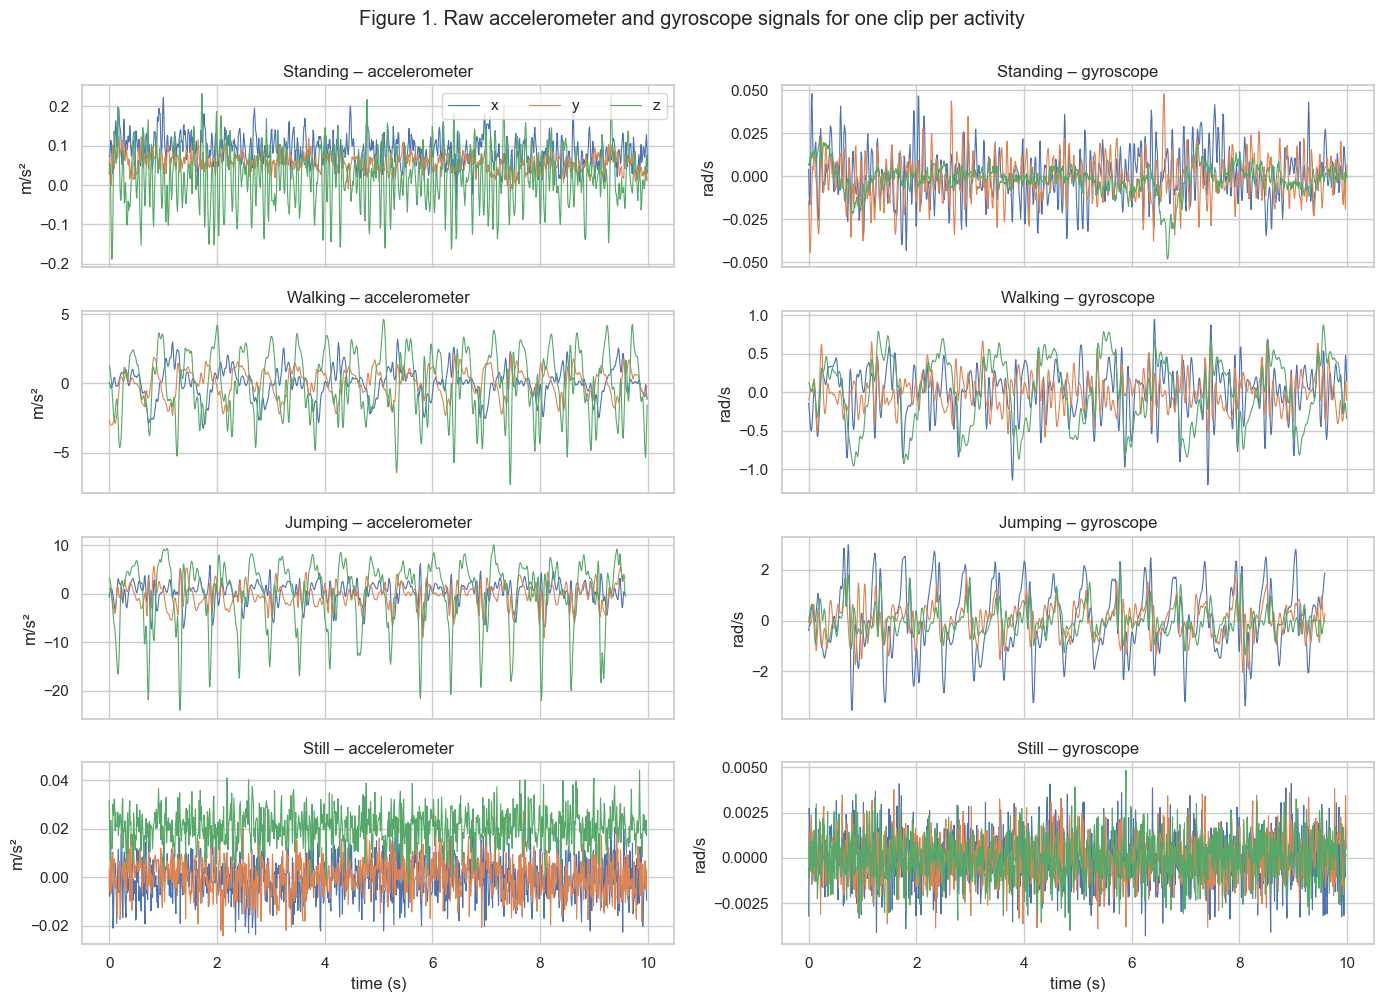

In [5]:
fig, axes = plt.subplots(len(ACTIVITIES), 2, figsize=(14, 10), sharex=True)
for row, activity in enumerate(ACTIVITIES):
    df = pd.read_csv(ROOT / "data" / "raw" / f"{activity}_01.csv")
    for col, (sensor, unit) in enumerate([("acc", "m/s²"), ("gyr", "rad/s")]):
        ax = axes[row, col]
        for axis in "xyz":
            ax.plot(df["seconds_elapsed"], df[f"{sensor}_{axis}"], lw=0.8, label=axis)
        ax.set_title(f"{activity.capitalize()} – {'accelerometer' if sensor == 'acc' else 'gyroscope'}")
        ax.set_ylabel(unit)
axes[0, 0].legend(loc="upper right", ncol=3)
axes[-1, 0].set_xlabel("time (s)")
axes[-1, 1].set_xlabel("time (s)")
fig.suptitle("Figure 1. Raw accelerometer and gyroscope signals for one clip per activity", y=1.0)
fig.tight_layout()
fig.savefig(PLOTS / "raw_signals.png", dpi=150, bbox_inches="tight")
plt.show()

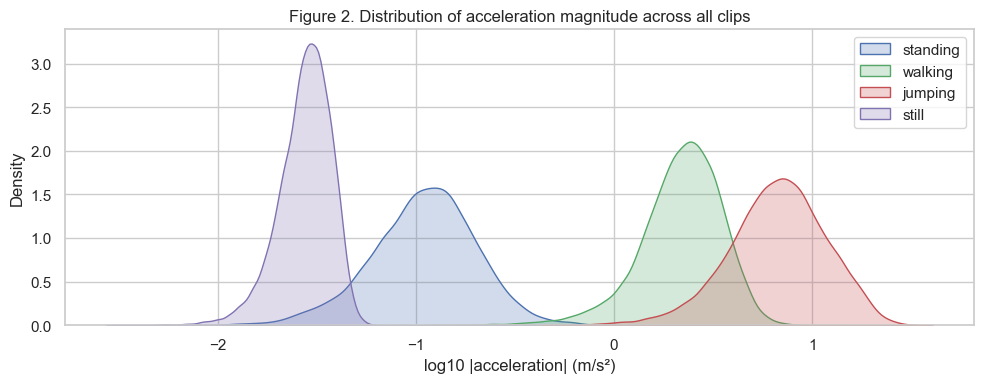

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
for activity in ACTIVITIES:
    mags = []
    for path in sorted((ROOT / "data" / "raw").glob(f"{activity}_*.csv")):
        df = pd.read_csv(path)
        mags.append(np.sqrt(df.acc_x**2 + df.acc_y**2 + df.acc_z**2))
    sns.kdeplot(np.log10(np.concatenate(mags) + 1e-3), ax=ax, label=activity,
                color=COLORS[activity], fill=True, alpha=0.25)
ax.set_xlabel("log10 |acceleration| (m/s²)")
ax.set_title("Figure 2. Distribution of acceleration magnitude across all clips")
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS / "acc_magnitude_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

### Unseen test sessions

The two test sessions were recorded as separate continuous sessions, not used in training, with the activities in a different order in each file.

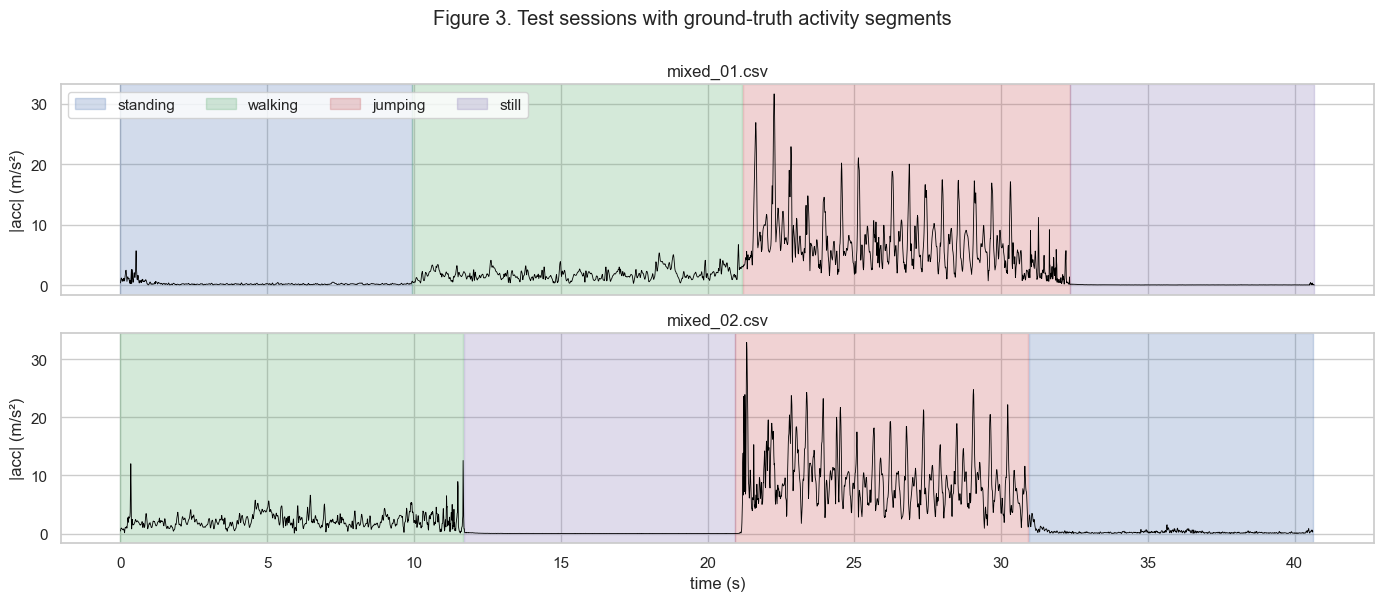

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for ax, name in zip(axes, ["mixed_01.csv", "mixed_02.csv"]):
    df = pd.read_csv(ROOT / "data" / "test" / name)
    mag = np.sqrt(df.acc_x**2 + df.acc_y**2 + df.acc_z**2)
    ax.plot(df["seconds_elapsed"], mag, color="black", lw=0.6)
    change = df["activity"].ne(df["activity"].shift()).cumsum()
    for _, seg in df.groupby(change):
        ax.axvspan(seg["seconds_elapsed"].iloc[0], seg["seconds_elapsed"].iloc[-1],
                   color=COLORS[seg["activity"].iloc[0]], alpha=0.25, label=seg["activity"].iloc[0])
    ax.set_title(name)
    ax.set_ylabel("|acc| (m/s²)")
handles, labels = axes[0].get_legend_handles_labels()
unique = dict(zip(labels, handles))
axes[0].legend(unique.values(), unique.keys(), loc="upper left", ncol=4)
axes[-1].set_xlabel("time (s)")
fig.suptitle("Figure 3. Test sessions with ground-truth activity segments", y=1.0)
fig.tight_layout()
fig.savefig(PLOTS / "test_sessions.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Preprocessing and windowing

| Step | Setting | Reason |
|---|---|---|
| Resampling | uniform 100 Hz grid | removes timestamp jitter; any phone recording at a different rate is interpolated onto the same grid, so every window has the same number of samples and the same FFT frequency bins |
| Low-pass filter | 4th-order Butterworth, 20 Hz, zero-phase | human motion is below 20 Hz; removes sensor noise without shifting events in time |
| Edge trim | 0.5 s at each end of training clips | removes the screen tap when starting and stopping a recording |
| Window | 2.0 s = 200 samples at 100 Hz | contains at least two walking or jumping cycles (about 1.5–2.5 Hz) and gives a 0.5 Hz FFT resolution (fs / N = 100 / 200) |
| Overlap | 50 % (step of 100 samples) | one observation per second for the HMM |

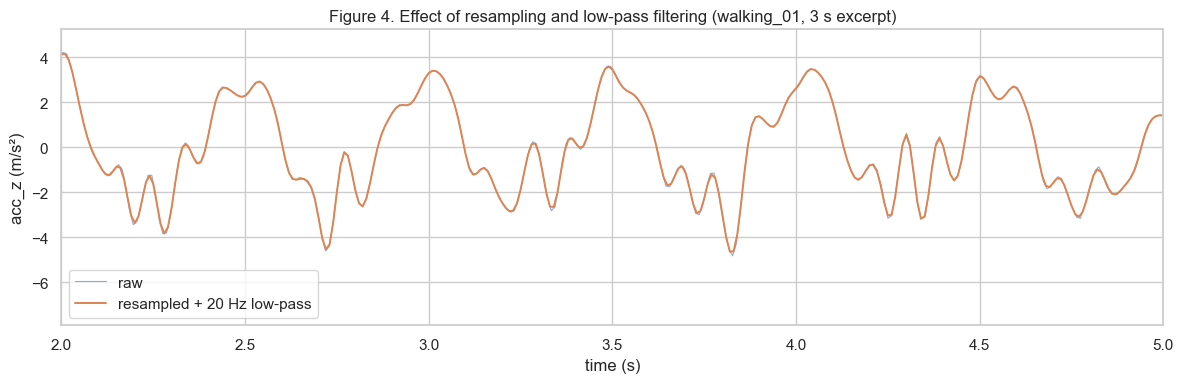

In [8]:
path = ROOT / "data" / "raw" / "walking_01.csv"
raw = pp.load_recording(path)
filtered = pp.lowpass_filter(pp.resample_uniform(raw))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(raw["seconds_elapsed"], raw["acc_z"], lw=0.8, alpha=0.6, label="raw")
ax.plot(filtered["seconds_elapsed"], filtered["acc_z"], lw=1.4, label="resampled + 20 Hz low-pass")
ax.set_xlim(2, 5)
ax.set_xlabel("time (s)")
ax.set_ylabel("acc_z (m/s²)")
ax.set_title("Figure 4. Effect of resampling and low-pass filtering (walking_01, 3 s excerpt)")
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS / "filtering.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
train_seqs = pp.load_training_windows()
test_seqs = pp.load_test_windows()

print(f"Window: {pp.WINDOW_S} s = {pp.WINDOW_SIZE} samples, step = {pp.STEP_SIZE} samples "
      f"({int(pp.OVERLAP * 100)}% overlap), FFT resolution = {pp.TARGET_FS / pp.WINDOW_SIZE} Hz")

window_counts = pd.DataFrame({
    "training": pd.Series(np.concatenate([s["labels"] for s in train_seqs])).value_counts(),
    **{s["file"]: pd.Series(s["labels"]).value_counts() for s in test_seqs},
}).reindex(ACTIVITIES).fillna(0).astype(int)
window_counts.loc["total"] = window_counts.sum()
window_counts

Window: 2.0 s = 200 samples, step = 100 samples (50% overlap), FFT resolution = 0.5 Hz


,training,mixed_01.csv,mixed_02.csv
standing,145,9,9
walking,149,12,11
jumping,135,11,10
still,148,7,9
total,577,39,39


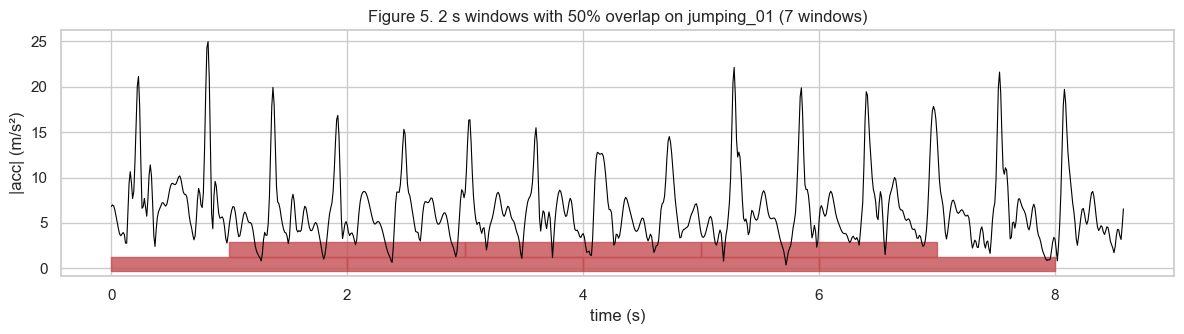

In [10]:
seq = next(s for s in train_seqs if s["file"] == "jumping_01.csv")
sig = seq["signal"]
mag = np.sqrt(sig.acc_x**2 + sig.acc_y**2 + sig.acc_z**2)

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(sig["seconds_elapsed"], mag, color="black", lw=0.8)
for i, start in enumerate(seq["start_s"]):
    ax.axvspan(start, start + pp.WINDOW_S, ymin=0.02 + 0.06 * (i % 2), ymax=0.08 + 0.06 * (i % 2),
               color=COLORS["jumping"], alpha=0.8)
ax.set_xlabel("time (s)")
ax.set_ylabel("|acc| (m/s²)")
ax.set_title(f"Figure 5. 2 s windows with 50% overlap on jumping_01 ({len(seq['start_s'])} windows)")
fig.tight_layout()
fig.savefig(PLOTS / "windowing.png", dpi=150, bbox_inches="tight")
plt.show()